# Experiment 2: TF-IDF targeted-training comparison

This notebook tests whether emphasizing uncertain examples improves the TF-IDF baseline. It compares:

- The unweighted baseline
- Hard-example weighting with several weights
- A random-control condition with the same number of weighted training examples

The validation set selects the best targeted condition. The test set is used only for the final comparison.

## Imports

In [7]:
import os
import pickle
import sys

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

sys.path.append("..")
from utils.hard_samples_identify import add_is_hard
from utils.preprocessing import LABELS, clean_text, encode_labels

np.random.seed(42)


## Load and preprocess the data

In [8]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

vectorizer = TfidfVectorizer(
    preprocessor=clean_text,
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df.sentence)
X_val = vectorizer.transform(val_df.sentence)
X_test = vectorizer.transform(test_df.sentence)

print(X_train.shape, X_val.shape, X_test.shape)


(2901, 39035) (967, 39035) (968, 39035)


## Train the baseline and calculate margins

The baseline probabilities are used to calculate margins. Each candidate threshold is derived from the training margins and then applied unchanged to validation and test. This keeps the meaning of each threshold consistent across the splits.

In [9]:
baseline_model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
baseline_model.fit(X_train, y_train)

train_probabilities = baseline_model.predict_proba(X_train)
val_probabilities = baseline_model.predict_proba(X_val)
test_probabilities = baseline_model.predict_proba(X_test)

def margins(probabilities):
    top_two = np.partition(probabilities, -2, axis=1)[:, -2:]
    return top_two.max(axis=1) - top_two.min(axis=1)

train_margins = margins(train_probabilities)
val_margins = margins(val_probabilities)
test_margins = margins(test_probabilities)


## Compare different hard-example thresholds

The threshold is calculated from the training margins only. The same threshold is then applied to validation and test. The selected examples receive a weight of `3.0`. A random-control model weights the same number of randomly selected training examples.

In [10]:
def train_model(weights):
    model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
    model.fit(X_train, y_train, sample_weight=weights)
    return model

def score(model, X, y, is_hard):
    predictions = model.predict(X)
    return {
        "accuracy": accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "hard_accuracy": accuracy_score(y[is_hard], predictions[is_hard]),
        "hard_f1": f1_score(y[is_hard], predictions[is_hard], average="macro"),
        "easy_accuracy": accuracy_score(y[~is_hard], predictions[~is_hard]),
        "easy_f1": f1_score(y[~is_hard], predictions[~is_hard], average="macro"),
    }

models = {"baseline": baseline_model}
validation_rows = []
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    train_is_hard = train_margins <= threshold
    val_is_hard = val_margins <= threshold
    test_is_hard = test_margins <= threshold

    if not train_is_hard.any() or not val_is_hard.any() or not test_is_hard.any():
        continue

    hard_name = f"hard_threshold_{threshold}"
    hard_weights = np.where(train_is_hard, 3.0, 1.0)
    models[hard_name] = train_model(hard_weights)
    validation_rows.append({
        "condition": hard_name,
        "threshold": threshold,
        "train_hard_count": train_is_hard.sum(),
        "val_hard_count": val_is_hard.sum(),
        "test_hard_count": test_is_hard.sum(),
        **score(models[hard_name], X_val, y_val, val_is_hard),
    })

    random_indices = np.random.default_rng(42).choice(
        len(y_train), size=train_is_hard.sum(), replace=False
    )
    random_weights = np.ones(len(y_train))
    random_weights[random_indices] = 3.0
    random_name = f"random_control_{threshold}"
    models[random_name] = train_model(random_weights)
    validation_rows.append({
        "condition": random_name,
        "threshold": threshold,
        "train_hard_count": train_is_hard.sum(),
        "val_hard_count": val_is_hard.sum(),
        "test_hard_count": test_is_hard.sum(),
        **score(models[random_name], X_val, y_val, val_is_hard),
    })

validation_results = pd.DataFrame(validation_rows).sort_values("hard_f1", ascending=False)
validation_results


,condition,threshold,train_hard_count,val_hard_count,test_hard_count,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1
9,random_control_0.6,0.6,100,469,455,0.775595,0.716668,0.631130,0.573836,0.911647,0.881466
8,hard_threshold_0.6,0.6,100,469,455,0.772492,0.711547,0.624733,0.562629,0.911647,0.881466
7,random_control_0.5,0.5,36,380,352,0.774560,0.711872,0.589474,0.533716,0.894378,0.854301
6,hard_threshold_0.5,0.5,36,380,352,0.771458,0.710255,0.581579,0.528530,0.894378,0.854301
4,hard_threshold_0.4,0.4,19,300,282,0.774560,0.716183,0.540000,0.498358,0.880060,0.835955
5,random_control_0.4,0.4,19,300,282,0.772492,0.711680,0.533333,0.489511,0.880060,0.835955
3,random_control_0.3,0.3,8,230,206,0.775595,0.715360,0.517391,0.474822,0.856174,0.808132
2,hard_threshold_0.3,0.3,8,230,206,0.773526,0.715516,0.508696,0.471671,0.856174,0.808132
1,random_control_0.2,0.2,5,153,133,0.778697,0.721765,0.490196,0.462370,0.832924,0.781945
0,hard_threshold_0.2,0.2,5,153,133,0.773526,0.715163,0.457516,0.431442,0.832924,0.781945


## Select the best condition

The best targeted threshold is selected using validation hard-subset macro-F1. If no targeted threshold beats the baseline validation hard-F1, the baseline remains the selected condition.

In [11]:
baseline_validation_hard_f1 = max(
    score(baseline_model, X_val, y_val, val_margins <= threshold)["hard_f1"]
    for threshold in thresholds
)

best_targeted = validation_results[
    validation_results.condition.str.startswith("hard_threshold_")
].iloc[0]

if best_targeted["hard_f1"] > baseline_validation_hard_f1:
    best_condition = best_targeted["condition"]
else:
    best_condition = "baseline"

print("Selected condition:", best_condition)


Selected condition: baseline


## Final test evaluation

The selected threshold is applied to the test margins. TP and FN are reported for hard examples in each sentiment class.


baseline
              precision    recall  f1-score   support

    negative       0.75      0.63      0.68       121
     neutral       0.82      0.87      0.84       575
    positive       0.71      0.66      0.68       272

    accuracy                           0.78       968
   macro avg       0.76      0.72      0.74       968
weighted avg       0.78      0.78      0.78       968

Hard negative: TP=6, FN=14
Hard neutral: TP=33, FN=29
Hard positive: TP=28, FN=23

baseline
              precision    recall  f1-score   support

    negative       0.75      0.63      0.68       121
     neutral       0.82      0.87      0.84       575
    positive       0.71      0.66      0.68       272

    accuracy                           0.78       968
   macro avg       0.76      0.72      0.74       968
weighted avg       0.78      0.78      0.78       968

Hard negative: TP=6, FN=14
Hard neutral: TP=33, FN=29
Hard positive: TP=28, FN=23


,condition,threshold,train_hard_count,test_hard_count,accuracy,macro_f1,hard_accuracy,hard_f1,easy_accuracy,easy_f1
0,baseline,0.2,5,133,0.779959,0.736191,0.503759,0.467763,0.823952,0.782631
1,baseline,0.2,5,133,0.779959,0.736191,0.503759,0.467763,0.823952,0.782631


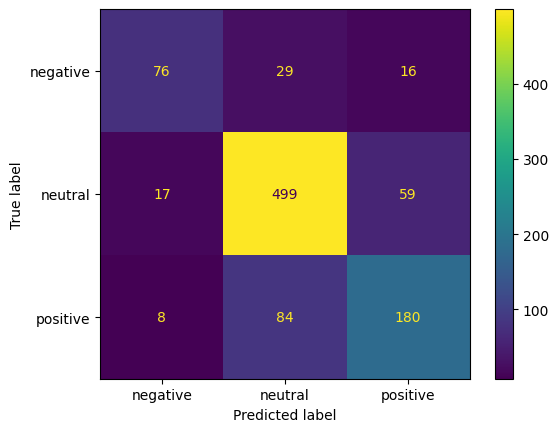

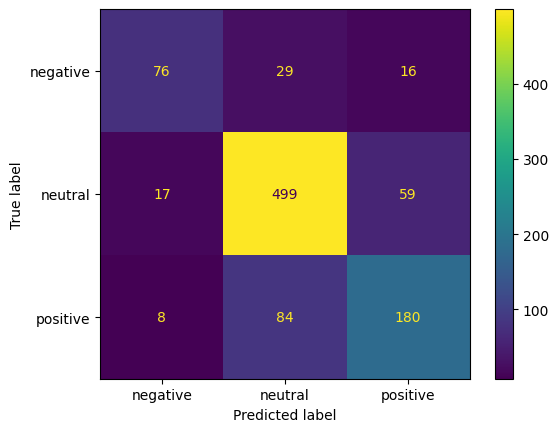

In [12]:
selected_threshold = 0.2 if best_condition == "baseline" else float(
    best_condition.rsplit("_", 1)[-1]
)
test_is_hard = test_margins <= selected_threshold

test_rows = []
for name in ["baseline", best_condition]:
    model = models[name]
    predictions = model.predict(X_test)
    row = {
        "condition": name,
        "threshold": selected_threshold,
        "train_hard_count": int((train_margins <= selected_threshold).sum()),
        "test_hard_count": int(test_is_hard.sum()),
        **score(model, X_test, y_test, test_is_hard),
    }
    test_rows.append(row)

    hard_true = y_test[test_is_hard]
    hard_pred = predictions[test_is_hard]
    print("\n" + name)
    print(classification_report(y_test, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=LABELS)

    for class_id, label in enumerate(LABELS):
        tp = ((hard_true == class_id) & (hard_pred == class_id)).sum()
        fn = ((hard_true == class_id) & (hard_pred != class_id)).sum()
        print(f"Hard {label}: TP={tp}, FN={fn}")

test_results = pd.DataFrame(test_rows)
test_results


## Save results


In [ ]:
os.makedirs("../models", exist_ok=True)

validation_results.to_csv("../results/experiment_2_validation_thresholds.csv", index=False)
test_results.to_csv("../results/experiment_2_test_thresholds.csv", index=False)

with open("../models/experiment_2_tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)
with open("../models/experiment_2_baseline_logreg.pkl", "wb") as f:
    pickle.dump(baseline_model, f)
with open("../models/experiment_2_selected_logreg.pkl", "wb") as f:
    pickle.dump(models[best_condition], f)
